### 선형회귀(Linear regression)
- 입력과 출력간의 관계를 (선형으로 놓고) 알아내는 것
    - 광고비와 매출액의 관계
- 목적 : 최적의 기울기와 절편 구하기
    - 실제값과 예측값의 오차가 최소화 되게 구하는 게 목적
    - MSE 사용
- 경사하강법 사용

In [1]:
import torch
import matplotlib.pyplot as plt

In [ ]:
x = torch.tensor([150., 160, 170, 175, 185])
y = torch.tensor([55, 70, 64, 80, 75.])
N = len(x)

plt.plot(x, y, 'o')

In [ ]:
# 임의로 기울기와 절편 설정
a = 0.45    # 기울기
b = -35     # 절편

x_plot = torch.linspace(145, 190, 100)
y_plot = a * x_plot + b

plt.figure()
plt.plot(x,y,'o')           # 실제 키와 몸무게
plt.plot(x_plot, y_plot, 'r')   # 임의로 만든 선형

(0.0, 1000.0)

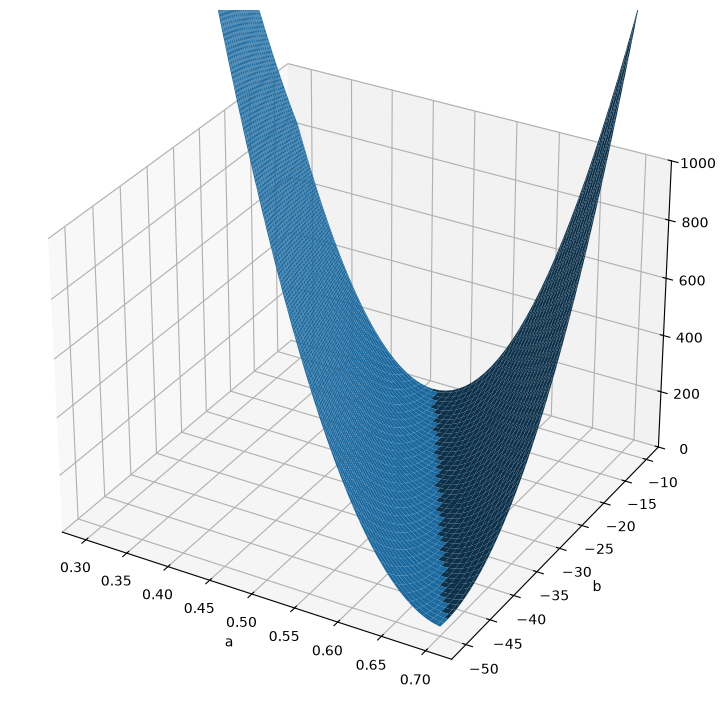

In [6]:
a = 0.5 + torch.linspace(-0.2, 0.2, 100)  # 0.3 ~ 0.7 기울기 후보군
b = -30 + torch.linspace(-20, 20, 100)  # -50 ~ -10  절편 후보군

L = torch.zeros(len(a), len(b))

for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N) :
            L[i,j] = L[i,j] + (y[n] - (a[i]*x[n]+b[j]))**2

L = L/N # MSE

plt.figure(figsize = [10, 9])
ax = plt.axes(projection="3d")
A, B = torch.meshgrid(a,b, indexing='ij')

ax.plot_surface(A, B, L)
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlim([0, 1000])

In [7]:
L

tensor([[4717.8999, 4662.7900, 4608.0068,  ...,  892.4518,  869.0127,
          845.8998],
        [4625.1914, 4570.6304, 4516.3955,  ...,  852.9494,  830.0588,
          807.4945],
        [4533.4097, 4479.3970, 4425.7109,  ...,  814.3732,  792.0311,
          770.0153],
        ...,
        [  37.8939,   35.9905,   34.4135,  ..., 1373.4280, 1403.1949,
         1433.2881],
        [  35.0339,   33.6789,   32.6504,  ..., 1423.7732, 1454.0889,
         1484.7303],
        [  33.1000,   32.2935,   31.8136,  ..., 1475.0457, 1505.9099,
         1537.1000]])

In [9]:
print(torch.min(L))
a_opt = A[L == torch.min(L)]
b_opt = B[L == torch.min(L)]

print(f'optimal a = {a_opt}')   # 기울기 최적
print(f'optimal b = {b_opt}')   # 절편 최적

tensor(29.0315)
optimal a = tensor([0.5626])
optimal b = tensor([-25.7576])


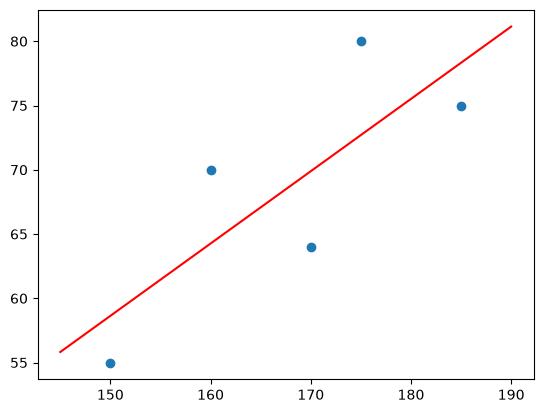

In [10]:
x_plot = torch.linspace(145, 190, 100)
y_plot = a_opt * x_plot + b_opt
plt.plot(x,y,'o')
plt.plot(x_plot, y_plot, 'r')

#### 경사하강법

In [36]:
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6  # 0.000003
EPOCH = 20

loss_history = []

for ep in range(EPOCH) :
    y_hat = a * x + b

    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss/N

    loss.backward()

    with torch.no_grad() :
        a -= LR * a.grad
        b -= LR * b.grad

    a.grad = torch.tensor([0.])
    b.grad = torch.tensor([0.])

    loss_history += [loss.item()]

    # print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    # print(f'Weight : {a.item():.4f}, Bias : {b.item():.4f}')

    # x_plot = torch.linspace(145, 190, 100)
    # y_plot = a.detach() * x_plot + b.detach()
    # plt.figure()
    # plt.plot(x, y, 'o')
    # plt.plot(x_plot, y_plot, 'r')
    # plt.title(f'Epoch {ep+1}')
    # plt.show()

    # print('-'*20)

Text(0.5, 1.0, 'Training Loss')

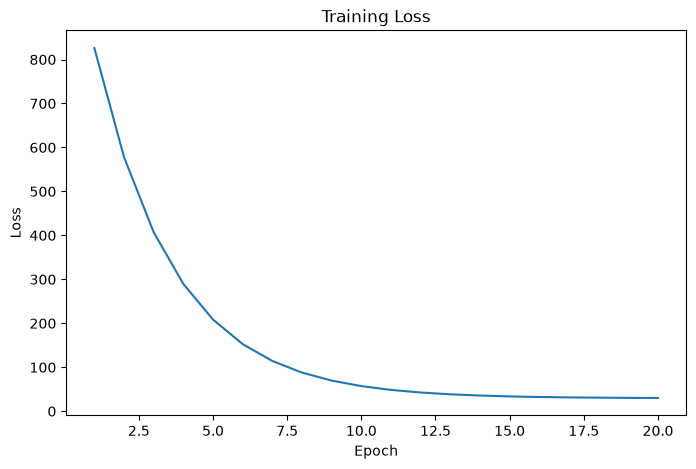

In [37]:
plt.figure(figsize=(8,5))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title('Training Loss')

In [ ]:
# 위는 어떻게 실행 되는지 알기 위해 한것이고
# 이게 PyTorch 정석
from torch import nn, optim

x = x.reshape(-1, 1)

model = nn.Linear(1,1)
model.weight.data = torch.tensor([[0.45]])
model.bias.data = torch.tensor([-35.])

LR = 3e-6
EPOCH = 20

optimizer = optim.SGD(model.parameters(), lr=LR)
cirterion = nn.MSELoss()

loss_history = []

for ep in range(EPOCH) :
    # 예측값
    y_hat = model(x)

    # loss
    loss = cirterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력은 본인마음대로
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    print(f'Weight : {model.weight.data.item():.4f}, Bias : {model.bias.data.item():.4f}')

    x_plot = torch.linspace(145, 190, 100)
    y_plot = model.weight.squeeze().detach() * x_plot + model.bias.detach()
    plt.figure()
    plt.plot(x,y,'o')
    plt.plot(x_plot, y_plot, 'm')
    plt.title(f'Epoch {ep+1}')
    plt.show()

    print('-' * 20)

Text(0.5, 1.0, 'Training Loss')

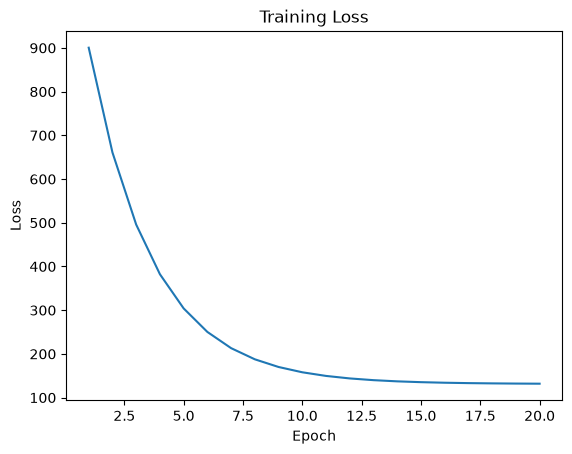

In [39]:
plt.figure()
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title('Training Loss')